# Component ablation on CosMx pancreas -- what changes in the attention flow without the local component?

The CosMx (melton25) counterpart of `notebooks/legnini_23/5_component_ablation.ipynb`. It answers
the reviewer question "what happens to the downstream analysis when a component is removed" for
the two readouts that come out of the transformer: the **cell-type net flow** derived from the
attention relevance matrix, and the **CLS token** attributions.

## The two sweeps

Both were built from **one** file, `interscale/config_files/sweeps/component_ablation_melton25.yaml`,
submitted twice with a different `--model_type`. That flag is not a config key -- `main_sweep.py`
reads it from argv and branches on it to pick the model class -- so it cannot be a sweep parameter,
which is why there are two sweeps rather than one with two arms.

| arm | `--model_type` | wandb sweep | checkpoints | transformer's input |
| --- | --- | --- | --- | --- |
| **Local + global** (full InterScale) | `CombinedModel` | [`5yluk4yv`](https://wandb.ai/francesca-drummer/InterScale_hyperparameter_sweep/sweeps/5yluk4yv) | `dual_melton25_regr_node_{40..44}_GCN_self-attn-transformer_model.pt` | the GCN's embedding of each cell's radius-110 neighbourhood |
| **Global only** | `GlobalModel` | [`5pk6w5t5`](https://wandb.ai/francesca-drummer/InterScale_hyperparameter_sweep/sweeps/5pk6w5t5) | `melton25_regr_node_{40..44}_self-attn-transformer_model.pt` | a 128-component PCA of the cell's own expression |

**What the sweeps did, in one line each:** a `method: grid` sweep over `optim.seed` in
`[40, 41, 42, 43, 44]` and nothing else -- 5 runs per arm -- with every other hyperparameter pinned
to the winning trial of the melton25 reconstruction sweep `sio2fsjm` (n_embed 128, GaussianNLL,
2-layer / 2-head transformer, dim_feedforward 256, lr 0.005, wd 0.01, batch 8, mask rate 0.1,
`max_seq_len` 1600), ranked and monitored on `val_concordance_corr`.

The two arms are therefore identical in every hyperparameter they can share. The three
`model.local_component.parameters.*` values in the yaml are the only exception, and they are not
an inconsistency: `config/sweep.py::build_sweep_config` drops parameters targeting a component the
model type does not have, so the global arm never receives them.

## What is being compared, and what it is not

Both readouts are read out of `obsm['_attn_matrix']` and `obs['_cls_horizontal'] / ['_cls_vertical']`,
which **both** model classes produce through the same `GlobalModule.evaluate` -> Chefer relevance
code path. That is what makes the arms comparable at all: the ablation changes what is fed into the
transformer, not how attention is extracted from it.

Three things are worth stating before reading any number below.

1. **There is no "local net flow" to compare against.** Attention, and therefore net flow and the
   CLS token, exists only in the transformer. A `LocalModel` produces neither, and in the combined
   model the *local decoder* (`layers['_y_pred_local']`) is a reconstruction head, not a second
   attention mechanism. So this notebook contrasts the two *arms*, not two decoders.

2. **The relevance matrix is dominated by its own diagonal** -- `generate_relevance` initialises
   `I` to `eye(n)` and adds to it, so ~99% of the mass is self-relevance. This does **not**
   contaminate the net flow: `compute_hierarchical_net_flow` returns `agg.T - agg`, and the
   diagonal of `I` only ever enters the sender==receiver blocks of `agg`, which the subtraction
   sends to exactly zero. Any *non-net* use of the same matrix would have to subtract it first.

3. **Net flow is antisymmetric**, so a 9x9 matrix holds 36 independent interactions and not 81.
   Every summary statistic below is taken over the upper triangle for that reason.

**Run this on a GPU node inside the interscale container, with more memory than the default.**
Inference materialises one `n_cells x max_seq_len` frame per model -- 151k x 1600 float32, ~1 GB,
and `get_model_output` assigns into it once per window -- on top of a copy of the slide's AnnData.
The stock `run_jupyter_interscale_cu128.sbatch` asks for 64 GB, which is enough only because the
loop frees each model before loading the next; submit it with `--mem=128G` if anything below is
changed to hold several models at once. A login node will not do.

The extraction loop caches its two CSVs, so re-running the notebook to redraw a figure does not
repeat the ten inferences.

In [1]:
import gc
import os
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

warnings.filterwarnings("ignore")

In [2]:
# LRZ home
if os.path.exists("/dss/dsshome1/05/di93tig"):
    print("LRZ cluster")
    CLUSTER = "LRZ"
    BASE_DIR_REPO = "/dss/dsshome1/05/di93tig/1_projects/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/dss/dssfs03/tumdss/pn36po/pn36po-dss-0002/di93tig/Projects/A3_InterScale"
elif os.path.exists("/home/icb/francesca.drummer/"):
    print("HPC cluster")
    CLUSTER = "HPC"
    BASE_DIR_REPO = "/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/"
else:
    print("unknown")
    CLUSTER = "unknown"

DATA = "melton25"

HPC cluster


In [3]:
# figures/config.yml is the house style for every figure in this repo -- palettes and rcParams
# both. Loaded through src/figure_style.py rather than re-read here, so nothing hardcodes a colour.
#
# sys.path is NOT used to reach it: InterScale_reproducibility/src/wandb.py shadows the real
# `wandb` package, and putting that directory on sys.path breaks `import wandb` further down.
import importlib.util

_spec = importlib.util.spec_from_file_location(
    "figure_style", os.path.join(BASE_DIR_REPO, "src", "figure_style.py")
)
figure_style = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(figure_style)

st = figure_style.FigureStyle(BASE_DIR_REPO)  # applies the rcParams on construction
CT_COLORS = st.cell_types(DATA)
print("continuous:", st.continuous_cmap, "| divergent:", st.divergent_cmap)

continuous: viridis | divergent: bwr


## The two arms

`ARMS` is the single place the two sweeps are described. Everything below iterates over it, so the
notebook never spells out one arm's checkpoint name or model class in a way the other arm does not
share.

In [4]:
import interscale
from interscale.config.registry import resolve_config
from interscale.config.sweep import apply_sweep_config, build_sweep_config, load_arms
from interscale.tl.utils import get_model_filename_prefix, set_full_reproducibility

INTERSCALE_REPO = Path(BASE_DIR_REPO).parent / "interscale"
REGISTRY = INTERSCALE_REPO / "config_files" / "registry.yaml"
SWEEP_YAML = INTERSCALE_REPO / "config_files" / "sweeps" / "component_ablation_melton25.yaml"

CKPT_DIR = Path(BASE_DIR_PROJECT) / "results" / "melton25_revision" / "component_ablation"
RESULTS_DIR = CKPT_DIR / "analysis"
FIG_DIR = Path(BASE_DIR_REPO) / "figures" / "melton25" / "component_ablation"

SEEDS = [40, 41, 42, 43, 44]
WANDB_ENTITY = "francesca-drummer"
WANDB_PROJECT = "InterScale_hyperparameter_sweep"

# Ordered global -> combined so every side-by-side figure reads "what the transformer does alone"
# on the left and "what it does with the local component" on the right.
ARMS = {
    "Global only": {
        "model_type": "GlobalModel",
        "sweep_id": "5pk6w5t5",
        "local": False,
        "global": True,
        "color": st.palette("Models")["PCATransformer"],
    },
    "Local + global": {
        "model_type": "CombinedModel",
        "sweep_id": "5yluk4yv",
        "local": True,
        "global": True,
        "color": st.palette("Models")["DualInterScale"],
    },
}

for d in (RESULTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
assert REGISTRY.exists() and SWEEP_YAML.exists()
print(f"registry    {REGISTRY}\nsweep yaml  {SWEEP_YAML}\ncheckpoints {CKPT_DIR}\nfigures     {FIG_DIR}")

registry    /home/icb/francesca.drummer/1-Projects/A3_InterScale/interscale/config_files/registry.yaml
sweep yaml  /home/icb/francesca.drummer/1-Projects/A3_InterScale/interscale/config_files/sweeps/component_ablation_melton25.yaml
checkpoints /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25_revision/component_ablation
figures     /home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/figures/melton25/component_ablation


In [5]:
import yaml


def build_cfg(arm: str, seed: int):
    '''Rebuild the exact config one (arm, seed) run trained with.

    Re-resolved from the registry and the sweep yaml rather than reconstructed from the wandb
    config blob, so the checkpoint path is derived by the same `get_model_filename_prefix` call
    that derived it at training time. The next cell then checks that against the `checkpoint_prefix`
    each run recorded in its own wandb summary.

    Note the trial dict is built for BOTH arms from the same yaml and handed to
    `build_sweep_config(model_type=...)`, exactly as `main_sweep.py` does -- that is what drops the
    local-component parameters for the global arm instead of applying keys it has no module for.
    '''
    model_type = ARMS[arm]["model_type"]
    with SWEEP_YAML.open() as f:
        yaml_config = yaml.safe_load(f)

    sweep_config, sweep_params = build_sweep_config(
        yaml_config,
        prediction_task="regression",
        model_type=model_type,
        metric={"name": "val_concordance_corr", "goal": "maximize"},
    )
    assert load_arms(yaml_config, sweep_config) is None, "this sweep declares no arms"

    # optim.seed is the only multi-valued parameter, so taking the first declared value of every
    # other one reproduces the trial exactly. Asserted rather than assumed: an edit that adds a
    # second value to any of them would otherwise silently rebuild the wrong config.
    for name, spec in sweep_config["parameters"].items():
        if name == "optim.seed":
            continue
        assert len(spec["values"]) == 1, (
            f"sweep parameter {name} has {len(spec['values'])} values; this notebook cannot infer "
            f"which one a run used. Read it from the run's wandb config instead."
        )

    trial = {k: v["values"][0] for k, v in sweep_config["parameters"].items()}
    trial["optim.seed"] = int(seed)

    cfg = resolve_config("melton25", "node_reg", registry_path=str(REGISTRY))
    cfg, _ = apply_sweep_config(
        cfg, "robustness", trial, model_type=model_type, sweep_params=sweep_params, arms=None
    )
    cfg.defrost()
    cfg.wandb.use = False  # loading a checkpoint must not open a wandb run
    cfg.model.save = str(CKPT_DIR) + os.sep
    cfg.freeze()
    return cfg


def checkpoint_prefix(arm: str, seed: int) -> str:
    a = ARMS[arm]
    return get_model_filename_prefix(build_cfg(arm, seed), a["local"], a["global"])


for arm in ARMS:
    print(f"{arm:15s} {checkpoint_prefix(arm, 40)}model.pt")

dropping sweep parameter not used by GlobalModel: model.local_component.parameters.hidden_dim
dropping sweep parameter not used by GlobalModel: model.local_component.parameters.num_layers
dropping sweep parameter not used by GlobalModel: model.local_component.parameters.dropout_local
applied sweep parameters: ['dataset.batch_size', 'dataset.mask_percentage', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.global_component.parameters.type_gex_embedding', 'model.n_embed', 'model.save', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'optim.monitor', 'optim.seed', 'optim.wd']
Global only     melton25_regr_node_40_self-attn-transformer_model.pt
applied sweep parameters: ['dataset.batch_size', 'dataset.mask_percentage', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_co

### The runs of record

Pulled from the wandb API so the table in this notebook is the sweep's own record rather than a
transcription of it, and so `checkpoint_prefix` -- written into each run's summary by
`main_sweep.py` after the trial was applied -- can be checked against the config rebuilt above. A
mismatch means the sweep yaml or the registry moved since the sweep ran, and every number below
would be attributed to the wrong configuration.

In [6]:
import wandb

api = wandb.Api()


def fetch_sweep_runs(arm: str) -> pd.DataFrame:
    sweep = api.sweep(f"{WANDB_ENTITY}/{WANDB_PROJECT}/{ARMS[arm]['sweep_id']}")
    rows = []
    for run in sweep.runs:
        cfg = {k: v for k, v in run.config.items() if not k.startswith("_")}
        s = dict(run.summary)
        rows.append(
            {
                "arm": arm,
                "run_id": run.id,
                "run_name": run.name,
                "state": run.state,
                "seed": cfg.get("optim.seed"),
                "checkpoint_prefix": s.get("checkpoint_prefix"),
                "val_concordance_corr": s.get("val_concordance_corr"),
                "val_pearson_corr": s.get("val_pearson_corr"),
                "val_r2": s.get("val_r2"),
                "val_mse": s.get("val_mse"),
                "test_concordance_corr": s.get("test_concordance_corr"),
                "test_r2": s.get("test_r2"),
                "epoch": s.get("epoch"),
                "total_parameters": s.get("total_parameters"),
            }
        )
    return pd.DataFrame(rows)


runs = pd.concat([fetch_sweep_runs(a) for a in ARMS], ignore_index=True).sort_values(["arm", "seed"])
runs.to_csv(RESULTS_DIR / "sweep_runs.csv", index=False)

# The rebuilt config must name the checkpoint the run actually wrote.
for _, r in runs.dropna(subset=["seed", "checkpoint_prefix"]).iterrows():
    expected = checkpoint_prefix(r["arm"], int(r["seed"]))
    assert expected == r["checkpoint_prefix"], (
        f"rebuilt config does not match run {r['run_id']}: {expected!r} vs {r['checkpoint_prefix']!r}"
    )
print("checkpoint prefixes agree with the sweep's own record")
runs[["arm", "seed", "state", "run_name", "val_concordance_corr", "val_r2", "epoch", "total_parameters"]]

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/icb/francesca.drummer/.netrc.


dropping sweep parameter not used by GlobalModel: model.local_component.parameters.hidden_dim
dropping sweep parameter not used by GlobalModel: model.local_component.parameters.num_layers
dropping sweep parameter not used by GlobalModel: model.local_component.parameters.dropout_local
applied sweep parameters: ['dataset.batch_size', 'dataset.mask_percentage', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.global_component.parameters.type_gex_embedding', 'model.n_embed', 'model.save', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'optim.monitor', 'optim.seed', 'optim.wd']
dropping sweep parameter not used by GlobalModel: model.local_component.parameters.hidden_dim
dropping sweep parameter not used by GlobalModel: model.local_component.parameters.num_layers
dropping sweep parameter not used by GlobalModel: model.local_component.parame

applied sweep parameters: ['dataset.batch_size', 'dataset.mask_percentage', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.global_component.parameters.type_gex_embedding', 'model.local_component.parameters.dropout_local', 'model.local_component.parameters.hidden_dim', 'model.local_component.parameters.num_layers', 'model.n_embed', 'model.save', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'optim.monitor', 'optim.seed', 'optim.wd']
applied sweep parameters: ['dataset.batch_size', 'dataset.mask_percentage', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.global_component.parameters.type_gex_embedding', 'model.local_component.parameters.dropout_local', 'model.local_component.para

,arm,seed,state,run_name,val_concordance_corr,val_r2,epoch,total_parameters
0,Global only,40,finished,melton25_regr_node_40_self-attn-transformer_,0.005501,-0.015728,69,391891
1,Global only,41,finished,melton25_regr_node_41_self-attn-transformer_,0.005057,-0.023269,40,391891
2,Global only,42,finished,melton25_regr_node_42_self-attn-transformer_,0.006373,-0.013115,77,391891
3,Global only,43,finished,melton25_regr_node_43_self-attn-transformer_,0.004947,-0.019632,40,391891
4,Global only,44,finished,melton25_regr_node_44_self-attn-transformer_,0.005059,-0.017304,50,391891
5,Local + global,40,finished,dual_melton25_regr_node_40_GCN_self-attn-trans...,0.015069,-0.021069,52,769318
6,Local + global,41,finished,dual_melton25_regr_node_41_GCN_self-attn-trans...,0.015134,-0.013919,59,769318
7,Local + global,42,finished,dual_melton25_regr_node_42_GCN_self-attn-trans...,0.015983,-0.012235,65,769318
8,Local + global,43,finished,dual_melton25_regr_node_43_GCN_self-attn-trans...,0.015733,-0.013904,68,769318
9,Local + global,44,finished,dual_melton25_regr_node_44_GCN_self-attn-trans...,0.015312,-0.019002,55,769318


In [7]:
# Reconstruction quality of the two arms, as the sweeps scored it. Not the point of this notebook,
# but it is the context every attention difference below has to be read against: an arm that
# reconstructs worse is not thereby wrong about who talks to whom, and an arm that reconstructs
# the same is not thereby making the same attributions.
summary = (
    runs.groupby("arm")[["val_concordance_corr", "val_r2", "test_concordance_corr", "total_parameters"]]
    .agg(["mean", "std"])
    .round(4)
)
summary

val_concordance_corr          val_r2          \
                               mean     std    mean     std   
arm                                                           
Global only                  0.0054  0.0006 -0.0178  0.0039   
Local + global               0.0154  0.0004 -0.0160  0.0038   

               test_concordance_corr         total_parameters       
                                mean     std             mean  std  
arm                                                                 
Global only                   0.0074  0.0009         391891.0  0.0  
Local + global                0.0157  0.0005         769318.0  0.0

## Data

Everything is evaluated on **one slide, `Run5211_S3`**, for the same reasons
`scripts/melton_jimenez_25/5a_sliding_window_attention.py` uses it: `split` on this dataset is
assigned per slide (train=S1, val=S2, test=S3), so S3 is the held-out slide for both arms; it
carries both conditions (ND and T1D); and squidpy's windows are built within `slide_fov`, so no
window straddles the slide boundary and subsetting leaves every window intact.

`remove_zero_expression_cells` runs **before** the slide subset, so the cell set is the one the
models were trained and validated on rather than one re-derived on a subset.

In [8]:
from interscale.tl import remove_zero_expression_cells

ANALYSIS_SLIDE = "Run5211_S3"
SLIDE_COL, SAMPLE_COL, CONDITION_COL, CELL_TYPE_COL = "slide", "slide_fov", "condition", "cell_type_coarse"

cfg0 = build_cfg("Local + global", SEEDS[0])
WINDOW_KEY = cfg0.dataset.sample_key[0]
MAX_SEQ_LEN = cfg0.model.global_component.parameters.max_seq_len

_cache = RESULTS_DIR / f"_slide_{ANALYSIS_SLIDE}.h5ad"
if _cache.exists():
    adata_ref = sc.read_h5ad(_cache)
else:
    _full = sc.read_h5ad(cfg0.dataset.h5ad_data)
    _full = remove_zero_expression_cells(_full)
    adata_ref = _full[_full.obs[SLIDE_COL].astype(str) == ANALYSIS_SLIDE].copy()
    del _full
    gc.collect()
    adata_ref.write_h5ad(_cache)
    print(f"cached analysis slide to {_cache}")

for col in (WINDOW_KEY, SAMPLE_COL, CONDITION_COL, CELL_TYPE_COL):
    adata_ref.obs[col] = adata_ref.obs[col].astype("category").cat.remove_unused_categories()

# A fixed cell-type order, used to reindex every flow matrix. Without it a condition or a seed in
# which one type happens to be absent would return a differently shaped matrix and the arms could
# not be stacked.
CELL_TYPES = list(adata_ref.obs[CELL_TYPE_COL].cat.categories)

sizes = adata_ref.obs[WINDOW_KEY].value_counts()
sizes = sizes[sizes > 0]
# Below max_seq_len, tl/padding.py random-subsamples each graph on every call instead of raising,
# so the predictions would come from a graph the model never saw.
assert sizes.max() <= MAX_SEQ_LEN, f"largest window {sizes.max()} > max_seq_len {MAX_SEQ_LEN}"

print(f"{adata_ref.n_obs} cells | {len(sizes)} windows (largest {sizes.max()}, max_seq_len {MAX_SEQ_LEN})")
print(f"{adata_ref.obs[SAMPLE_COL].nunique()} FOVs | conditions {dict(adata_ref.obs[CONDITION_COL].value_counts())}")
print(f"cell types: {CELL_TYPES}")

applied sweep parameters: ['dataset.batch_size', 'dataset.mask_percentage', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.global_component.parameters.type_gex_embedding', 'model.local_component.parameters.dropout_local', 'model.local_component.parameters.hidden_dim', 'model.local_component.parameters.num_layers', 'model.n_embed', 'model.save', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'optim.monitor', 'optim.seed', 'optim.wd']


151595 cells | 215 windows (largest 1600, max_seq_len 1600)
25 FOVs | conditions {'T1D': np.int64(100230), 'ND': np.int64(51365)}
cell types: ['Acinar', 'Alpha', 'Beta', 'Ductal', 'Endocrine', 'Endothelial', 'Fibroblasts', 'Immune', 'Mast']


## Inference and extraction

One pass per (arm, seed): load the checkpoint, run `get_model_output`, and immediately reduce the
attention matrix to the two things this notebook needs -- the hierarchical net flow and the
per-cell CLS attributions. The attention matrix itself is dropped before the next model is loaded;
holding all ten would be ~10 GB.

Two details that a reload gets silently wrong if they are skipped:

* `split_key=None` in `_setup_anndata`. It asserts the split column contains both `train` and
  `val`, and this AnnData is one held-out slide, so it is entirely `test`. Nothing on the inference
  path reads the registered split field -- `get_model_output` goes through `prepare_a2d_dataset`,
  which does not split.
* `CombinedModel.load` / `GlobalModel.load` use `strict=False`. Read the missing/unexpected-key
  warnings they print: a shape mismatch comes back as a silently wrong model, not an error. For the
  **global** arm one of those keys matters especially -- `pca_fitted_`, `pca_mean_`,
  `pca_components_` carry the fitted PCA basis that stands in for the local encoder. They are
  asserted below, because without them the model would refit the basis on the evaluation data and
  the trained transformer would be reading a differently rotated space.

In [9]:
from interscale.evaluation.graph_classification import scale_cls_by_sample
from interscale.evaluation.net_streams import compute_hierarchical_net_flow

CLS_COLS = ["_cls_horizontal", "_cls_vertical"]
CLS_SCALED = [f"{c}_scaled" for c in CLS_COLS]


def load_model(arm: str, seed: int, adata):
    '''Load one (arm, seed) checkpoint against `adata`, ready for inference.'''
    a = ARMS[arm]
    cfg = build_cfg(arm, seed)
    ModelCls = getattr(interscale.model, a["model_type"])

    ModelCls._setup_anndata(
        adata=adata,
        prediction_task=cfg.dataset.prediction_task,
        layer_key=cfg.dataset.layer_key,
        sample_key_list=cfg.dataset.sample_key,
        prediction_obs=cfg.dataset.prediction_obs,
        split_key=None,
        view_registry=False,
    )
    set_full_reproducibility(cfg.optim.seed)
    model = ModelCls.load(
        str(CKPT_DIR), adata, cfg, local_component=a["local"], global_component=a["global"]
    )
    if a["model_type"] == "GlobalModel":
        assert bool(model.module.pca_fitted_), (
            "the checkpoint carries no fitted PCA basis, so inference would refit it on this data "
            "and the transformer would read a different space than it was trained on. Retrain this "
            "arm with the current interscale (see tests/test_global_pca_persistence.py)."
        )
    return model, cfg

In [10]:
def net_flow_long(adata, arm, seed, compute_net=True) -> pd.DataFrame:
    '''Per-condition cell-type net flow for one model, as tidy rows.

    `compute_net=True` (the default) returns `agg.T - agg`, i.e. an ANTISYMMETRIC matrix whose
    sender==receiver entries are exactly zero -- which is also what removes the relevance matrix's
    `eye(n)` initialisation from the result.

    Every matrix is reindexed onto the fixed `CELL_TYPES` order: a condition in which one type is
    absent would otherwise come back with fewer rows and the arms could not be stacked.
    '''
    # compute_net=False returns the DIRECTED aggregated attention (agg.T with the diagonal
    # zeroed) instead of agg.T - agg. The rank analysis needs it: "rank receivers by attention
    # weight" is a statement about attention, and a net flow is a signed difference in which a
    # top-ranked receiver means "most net outward", not "most attended".
    res = compute_hierarchical_net_flow(
        adata,
        window_key=WINDOW_KEY,
        sample_key=SAMPLE_COL,
        condition_key=CONDITION_COL,
        cell_type_col=CELL_TYPE_COL,
        compute_net=compute_net,
    )
    # Laid out against an explicit (sender, receiver) product rather than by stacking each frame
    # separately: `DataFrame.stack` drops NaN, so a missing cell type could shorten one of the two
    # differently from the other and silently misalign flow against its standard deviation.
    idx = pd.MultiIndex.from_product([CELL_TYPES, CELL_TYPES], names=["sender", "receiver"])
    rows = []
    for condition, d in res.items():
        m = d["mean"].reindex(index=CELL_TYPES, columns=CELL_TYPES)
        s = d["std"].reindex(index=CELL_TYPES, columns=CELL_TYPES)
        long = pd.DataFrame(
            {"flow": m.to_numpy().ravel(), "fov_std": s.to_numpy().ravel()}, index=idx
        ).reset_index()
        long.insert(0, "condition", condition)
        rows.append(long)
    out = pd.concat(rows, ignore_index=True)
    out.insert(0, "seed", seed)
    out.insert(0, "arm", arm)
    return out


def cls_long(adata, arm, seed) -> pd.DataFrame:
    '''Per-cell CLS attributions for one model, min-max scaled within each window.

    Raw CLS relevances are ~1e-6 and scale with the window's size, so they are not comparable
    across windows -- `scale_cls_by_sample` is the repo's existing fix for exactly that. The
    scaling is per window, so it is applied identically to both arms and cannot by itself create
    a difference between them.
    '''
    scale_cls_by_sample(adata, sample_key=WINDOW_KEY, cls_columns=CLS_COLS, inplace=True, suffix="_scaled")
    out = adata.obs[[CELL_TYPE_COL, CONDITION_COL, SAMPLE_COL, WINDOW_KEY, *CLS_COLS, *CLS_SCALED]].copy()
    out.insert(0, "seed", seed)
    out.insert(0, "arm", arm)
    return out

In [11]:
FLOW_CSV = RESULTS_DIR / "net_flow_by_arm_seed.csv"
DIR_CSV = RESULTS_DIR / "directed_attention_by_arm_seed.csv"
CLS_CSV = RESULTS_DIR / "cls_by_arm_seed_celltype.csv"
RECOMPUTE = not (FLOW_CSV.exists() and DIR_CSV.exists() and CLS_CSV.exists())

if RECOMPUTE:
    flow_rows, dir_rows, cls_rows = [], [], []
    for arm in ARMS:
        for seed in SEEDS:
            print(f"=== {arm} | seed {seed} ===", flush=True)
            adata = adata_ref.copy()  # get_model_output rewrites obs_names, so never reuse one
            model, cfg = load_model(arm, seed, adata)

            # prefix="" writes obsm _attn_matrix/_global_emb, obs _cls_horizontal/_cls_vertical.
            adata = model.get_model_output(adata, prefix="")

            flow_rows.append(net_flow_long(adata, arm, seed, compute_net=True))
            dir_rows.append(net_flow_long(adata, arm, seed, compute_net=False))
            # Reduced to per-(cell type, condition) means here rather than kept per cell: the
            # per-cell frame is 151k rows x 10 models, and every figure below groups it anyway.
            per_cell = cls_long(adata, arm, seed)
            cls_rows.append(
                per_cell.groupby([CELL_TYPE_COL, CONDITION_COL], observed=True)[CLS_SCALED]
                .mean()
                .reset_index()
                .assign(arm=arm, seed=seed)
            )

            del model, adata, per_cell
            gc.collect()
            try:
                import torch

                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            except ImportError:
                pass

    flow = pd.concat(flow_rows, ignore_index=True)
    directed = pd.concat(dir_rows, ignore_index=True)
    cls = pd.concat(cls_rows, ignore_index=True)
    flow.to_csv(FLOW_CSV, index=False)
    directed.to_csv(DIR_CSV, index=False)
    cls.to_csv(CLS_CSV, index=False)
else:
    print(f"reusing cached extraction:\n  {FLOW_CSV}\n  {DIR_CSV}\n  {CLS_CSV}")
    flow = pd.read_csv(FLOW_CSV)
    directed = pd.read_csv(DIR_CSV)
    cls = pd.read_csv(CLS_CSV)

print(flow.shape, cls.shape)
assert set(flow["arm"]) == set(ARMS) and set(flow["seed"]) == set(SEEDS)
flow.head()

reusing cached extraction:
  /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25_revision/component_ablation/analysis/net_flow_by_arm_seed.csv
  /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25_revision/component_ablation/analysis/directed_attention_by_arm_seed.csv
  /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25_revision/component_ablation/analysis/cls_by_arm_seed_celltype.csv
(1620, 7) (180, 6)


,arm,seed,condition,sender,receiver,flow,fov_std
0,Global only,40,T1D,Acinar,Acinar,0.000000,0.000000
1,Global only,40,T1D,Acinar,Alpha,0.012549,0.129669
2,Global only,40,T1D,Acinar,Beta,-0.002414,0.143115
3,Global only,40,T1D,Acinar,Ductal,0.108917,0.141032
4,Global only,40,T1D,Acinar,Endocrine,0.136452,0.088253


## Net flow

`plot_global_directionality` draws flow as colour and **consistency** (1/std) as dot size. The std
handed to it here is the spread **across the five seeds**, not across FOVs -- so a large dot means
"the five independently trained models agree on this interaction", which is the claim the seed
sweep exists to support. The per-FOV std the function was originally fed is kept in the
`fov_std` column if the other reading is wanted.

Both panels are drawn with the same colour limits. Without that, seaborn normalises each panel to
its own range and equal colours in the two panels would stand for different magnitudes -- which is
exactly the comparison this figure is for.

In [12]:
# Cross-seed mean and SD per (arm, condition, sender, receiver).
agg = (
    flow.groupby(["arm", "condition", "sender", "receiver"], observed=True)["flow"]
    .agg(mean="mean", std="std", n="size")
    .reset_index()
)
assert (agg["n"] == len(SEEDS)).all(), "every cell-type pair must be present for all five seeds"


def as_matrix(df, value):
    return df.pivot(index="sender", columns="receiver", values=value).reindex(
        index=CELL_TYPES, columns=CELL_TYPES
    )


CONDITIONS = sorted(agg["condition"].unique())
print("conditions:", CONDITIONS)
agg.head()

conditions: ['ND', 'T1D']


,arm,condition,sender,receiver,mean,std,n
0,Global only,ND,Acinar,Acinar,0.000000,0.000000,5
1,Global only,ND,Acinar,Alpha,-0.054311,0.246538,5
2,Global only,ND,Acinar,Beta,-0.145324,0.282011,5
3,Global only,ND,Acinar,Ductal,0.047329,0.426658,5
4,Global only,ND,Acinar,Endocrine,-0.060744,0.335464,5


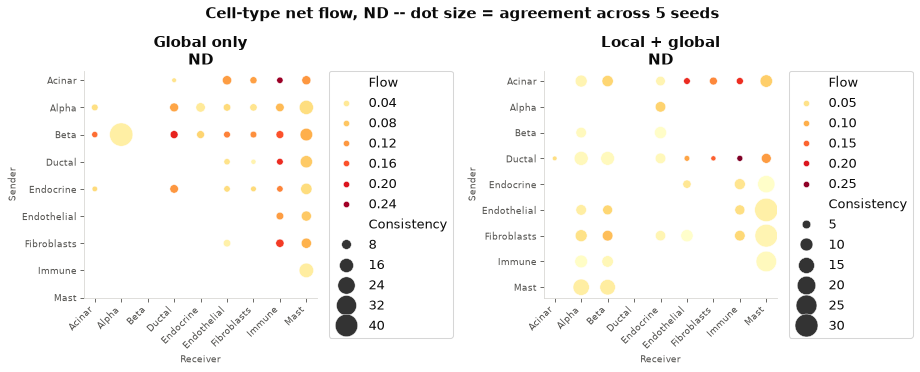

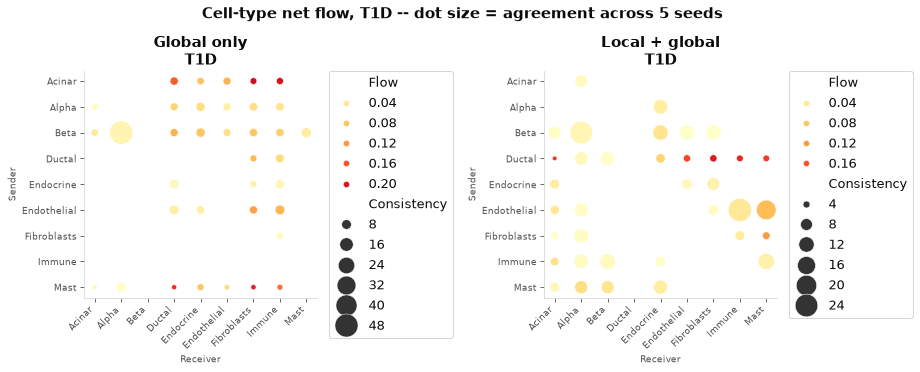

In [13]:
from interscale.evaluation import plot_global_directionality

# Shared across every panel so colour means the same thing everywhere.
VMAX = float(agg["mean"].abs().max())

for condition in CONDITIONS:
    # No sharey: `plot_global_directionality` sets the y ticks on the axes it is given, and a
    # shared y axis hides the inner panel's tick labels behind that.
    fig, axes = plt.subplots(1, len(ARMS), figsize=(6.2 * len(ARMS), 5.0))
    for ax, (arm, meta) in zip(np.atleast_1d(axes), ARMS.items()):
        sub = agg[(agg["arm"] == arm) & (agg["condition"] == condition)]
        plot_global_directionality(
            as_matrix(sub, "mean"),
            as_matrix(sub, "std"),
            only_positive=True,
            title=f"{arm}\n{condition}",
            ax=ax,
            vmin=0,
            vmax=VMAX,
        )
        ax.set_xlabel("Receiver")
    fig.suptitle(f"Cell-type net flow, {condition} -- dot size = agreement across {len(SEEDS)} seeds", **st.title_kw)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"net_flow_{condition}.png", dpi=300, bbox_inches="tight")
    plt.show()

### What actually moved

The dot plots show each arm; this shows the difference between them. Only the **upper triangle** is
summarised: the matrix is antisymmetric, so the lower triangle is the same 36 interactions with
their signs flipped and counting both would double every statistic.

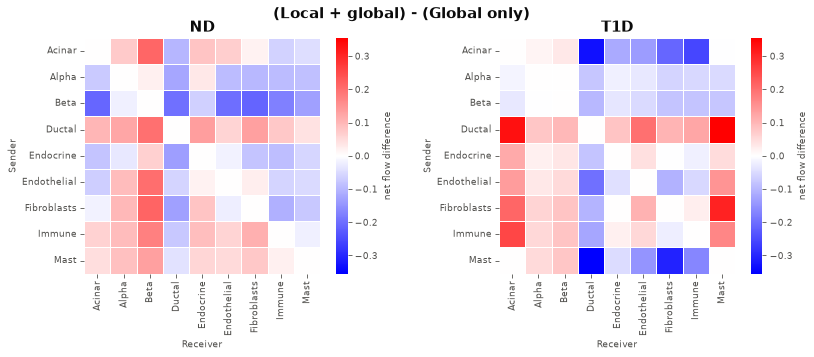

In [14]:
iu = np.triu_indices(len(CELL_TYPES), k=1)

diff_frames = {}
for condition in CONDITIONS:
    m = {arm: as_matrix(agg[(agg["arm"] == arm) & (agg["condition"] == condition)], "mean") for arm in ARMS}
    diff_frames[condition] = m["Local + global"] - m["Global only"]

fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(5.6 * len(CONDITIONS), 4.6))
lim = max(np.abs(d.to_numpy()).max() for d in diff_frames.values())
for ax, condition in zip(np.atleast_1d(axes), CONDITIONS):
    sns.heatmap(
        diff_frames[condition],
        ax=ax,
        cmap=st.divergent_cmap,
        vmin=-lim,
        vmax=lim,
        square=True,
        linewidths=0.5,
        cbar_kws={"label": "net flow difference"},
    )
    ax.set_title(f"{condition}", **st.title_kw)
    ax.set_xlabel("Receiver")
    ax.set_ylabel("Sender")
fig.suptitle("(Local + global) - (Global only)", **st.title_kw)
fig.tight_layout()
fig.savefig(FIG_DIR / "net_flow_difference.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
from scipy.stats import spearmanr

# How much of the flow structure is shared between the arms, and how that compares to the spread
# BETWEEN SEEDS of one arm. The second number is the scale the first has to be read against: an
# arm-to-arm correlation of 0.6 means something quite different if two seeds of the same arm
# already only agree at 0.65.
rows = []
for condition in CONDITIONS:
    mats = {
        (arm, seed): as_matrix(
            flow[(flow["arm"] == arm) & (flow["seed"] == seed) & (flow["condition"] == condition)], "flow"
        ).to_numpy()[iu]
        for arm in ARMS
        for seed in SEEDS
    }
    means = {
        arm: as_matrix(agg[(agg["arm"] == arm) & (agg["condition"] == condition)], "mean").to_numpy()[iu]
        for arm in ARMS
    }

    within = {
        arm: [
            spearmanr(mats[(arm, a)], mats[(arm, b)]).statistic
            for i, a in enumerate(SEEDS)
            for b in SEEDS[i + 1 :]
        ]
        for arm in ARMS
    }
    rows.append(
        {
            "condition": condition,
            "between arms (cross-seed means)": spearmanr(*means.values()).statistic,
            **{f"within {arm} (seed pairs)": float(np.mean(v)) for arm, v in within.items()},
            "|difference| median": float(np.median(np.abs(diff_frames[condition].to_numpy()[iu]))),
            "|difference| max": float(np.abs(diff_frames[condition].to_numpy()[iu]).max()),
        }
    )

pd.DataFrame(rows).set_index("condition").round(3)

,between arms (cross-seed means),within Global only (seed pairs),within Local + global (seed pairs),|difference| median,|difference| max
condition,,,,,
ND,0.087,-0.021,-0.057,0.079,0.215
T1D,-0.272,-0.078,-0.025,0.080,0.355


In [16]:
# The individual interactions that move most, with the cross-seed SD of each arm next to them --
# a large shift that is smaller than the seed spread is not a shift.
top = []
for condition in CONDITIONS:
    d = diff_frames[condition]
    for i, j in zip(*iu):
        s, r = CELL_TYPES[i], CELL_TYPES[j]
        row = {"condition": condition, "sender": s, "receiver": r, "difference": d.iloc[i, j]}
        for arm in ARMS:
            a = agg[(agg["arm"] == arm) & (agg["condition"] == condition) & (agg["sender"] == s) & (agg["receiver"] == r)]
            row[f"{arm} mean"] = float(a["mean"].iloc[0])
            row[f"{arm} SD"] = float(a["std"].iloc[0])
        top.append(row)

top = pd.DataFrame(top)
top["|difference|"] = top["difference"].abs()
top["exceeds seed spread"] = top["|difference|"] > (top["Global only SD"] + top["Local + global SD"])
top.sort_values("|difference|", ascending=False).head(12).round(4)

,condition,sender,receiver,difference,Global only mean,Global only SD,Local + global mean,Local + global SD,|difference|,exceeds seed spread
61,T1D,Ductal,Mast,0.3547,-0.1819,0.5325,0.1729,0.2605,0.3547,False
38,T1D,Acinar,Ductal,-0.3315,0.1544,0.1767,-0.1771,0.3502,0.3315,False
70,T1D,Fibroblasts,Mast,0.3058,-0.1902,0.4823,0.1156,0.2225,0.3058,False
42,T1D,Acinar,Immune,-0.2563,0.2040,0.2462,-0.0523,0.2023,0.2563,False
18,ND,Beta,Fibroblasts,-0.2145,0.1276,0.2443,-0.0870,0.1401,0.2145,False
1,ND,Acinar,Beta,0.2125,-0.1453,0.2820,0.0672,0.1261,0.2125,False
41,T1D,Acinar,Fibroblasts,-0.2117,0.2088,0.2679,-0.0029,0.2085,0.2117,False
17,ND,Beta,Endothelial,-0.2014,0.1350,0.2403,-0.0664,0.1603,0.2014,False
58,T1D,Ductal,Endothelial,0.1995,-0.0330,0.1334,0.1664,0.2366,0.1995,False
15,ND,Beta,Ductal,-0.1992,0.1881,0.1825,-0.0111,0.0881,0.1992,False


### The least divergent pair of seeds

Averaging over seeds destroyed the signal, so this asks a narrower question: **taking one global
model and one combined model at a time, how close can the two arms get?** All 5 x 5 = 25 cross-arm
seed pairings are scored, and the single closest one is shown on its own -- one global run against
one combined run, no averaging and therefore no standard deviation anywhere in the panel.

Divergence is the **RMS of the difference over the 36 upper-triangle entries**, which is exactly
the quantity the difference heatmap draws. Spearman is reported beside it because the two can
disagree: a pair can be close in magnitude while ordering the interactions differently.

Two things this figure is not:

* **It is not an estimate.** The minimum of 25 noisy numbers is biased low by construction --
  picking the best of 25 draws finds a good draw whether or not there is anything to find. The
  full 5 x 5 grid is printed below it so the selection is visible rather than asserted, and the
  panel is labelled with the seeds it came from.
* **It is not meaningful on its own scale.** The reference is the `within-arm` row of the same
  table: the divergence between two seeds of the *same* arm. If the best cross-arm pair is no
  more divergent than a typical same-arm pair, then those two particular runs differ no more than
  two runs of one arm do -- which is a statement about the size of the arm effect against seed
  noise, and is the only comparison here that survives the reproducibility problem.

In [17]:
from itertools import product

GLOBAL_ARM, COMBINED_ARM = "Global only", "Local + global"


def flow_matrix(arm, seed, condition):
    # One model's net flow as a cell-type x cell-type frame.
    sub = flow[(flow["arm"] == arm) & (flow["seed"] == seed) & (flow["condition"] == condition)]
    return as_matrix(sub, "flow")


def upper(mat):
    # The 36 independent interactions. The matrix is antisymmetric, so the lower triangle is the
    # same numbers negated and including it would double-count every pair.
    return mat.to_numpy()[iu]


# Every (global seed, combined seed) pairing, per condition.
pair_rows = []
for condition in CONDITIONS:
    for sg, sc in product(SEEDS, SEEDS):
        g = upper(flow_matrix(GLOBAL_ARM, sg, condition))
        c = upper(flow_matrix(COMBINED_ARM, sc, condition))
        d = c - g
        pair_rows.append(
            {
                "condition": condition,
                "global_seed": sg,
                "combined_seed": sc,
                "rms": float(np.sqrt((d**2).mean())),
                "max_abs": float(np.abs(d).max()),
                "spearman": float(spearmanr(g, c).statistic),
            }
        )
pairs = pd.DataFrame(pair_rows)

# The reference scale: the same statistic between two seeds of the SAME arm (10 pairs per arm).
ref_rows = []
for condition in CONDITIONS:
    for arm in ARMS:
        for i, a in enumerate(SEEDS):
            for b in SEEDS[i + 1 :]:
                d = upper(flow_matrix(arm, a, condition)) - upper(flow_matrix(arm, b, condition))
                ref_rows.append(
                    {"condition": condition, "arm": arm, "rms": float(np.sqrt((d**2).mean()))}
                )
within = pd.DataFrame(ref_rows)

best = pairs.loc[pairs.groupby("condition")["rms"].idxmin()].set_index("condition")

scale = pd.concat(
    [
        pairs.groupby("condition")["rms"].agg(["min", "median", "max"]).add_prefix("cross-arm "),
        within.groupby(["condition", "arm"])["rms"].median().unstack().add_prefix("within-arm median "),
    ],
    axis=1,
)
print("selected pairing per condition:")
print(best[["global_seed", "combined_seed", "rms", "spearman"]].round(3).to_string())
print()
scale.round(3)

selected pairing per condition:
           global_seed  combined_seed    rms  spearman
condition                                             
ND                  40             43  0.133     0.486
T1D                 40             44  0.202     0.477



,cross-arm min,cross-arm median,cross-arm max,within-arm median Global only,within-arm median Local + global
condition,,,,,
ND,0.133,0.251,0.440,0.263,0.277
T1D,0.202,0.301,0.445,0.348,0.208


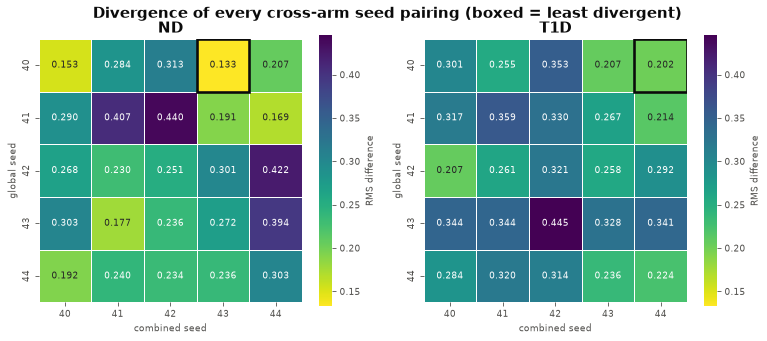

In [18]:
# The full 5x5 grid the pairing was chosen from, so the selection is visible. A grid that is flat
# means the choice barely mattered; a grid with one clear minimum means it did.
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(5.2 * len(CONDITIONS), 4.4))
vmin, vmax = pairs["rms"].min(), pairs["rms"].max()
for ax, condition in zip(np.atleast_1d(axes), CONDITIONS):
    grid = pairs[pairs["condition"] == condition].pivot(
        index="global_seed", columns="combined_seed", values="rms"
    )
    sns.heatmap(
        grid, ax=ax, cmap=st.continuous_cmap + "_r", vmin=vmin, vmax=vmax, annot=True, fmt=".3f",
        square=True, linewidths=0.5, cbar_kws={"label": "RMS difference"},
    )
    # Ring the cell that was selected.
    r = best.loc[condition]
    ax.add_patch(
        plt.Rectangle(
            (list(grid.columns).index(r["combined_seed"]), list(grid.index).index(r["global_seed"])),
            1, 1, fill=False, edgecolor=figure_style.INK, lw=2.5,
        )
    )
    ax.set_title(f"{condition}", **st.title_kw)
    ax.set_xlabel("combined seed")
    ax.set_ylabel("global seed")
fig.suptitle("Divergence of every cross-arm seed pairing (boxed = least divergent)", **st.title_kw)
fig.tight_layout()
fig.savefig(FIG_DIR / "net_flow_pair_divergence_grid.png", dpi=300, bbox_inches="tight")
plt.show()

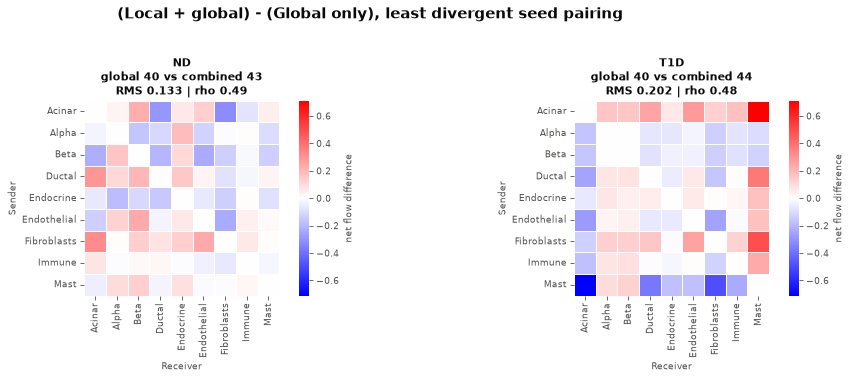

In [19]:
# The selected pairing, on its own. One global run minus one combined run -- no averaging, so
# there is no standard deviation to show and none is implied.
# 6.6in per panel and a 3-line title at 11pt: at the previous width the two panels' titles
# ran into each other.
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(6.6 * len(CONDITIONS), 4.8))
best_diff = {
    condition: (
        flow_matrix(COMBINED_ARM, best.loc[condition, "combined_seed"], condition)
        - flow_matrix(GLOBAL_ARM, best.loc[condition, "global_seed"], condition)
    )
    for condition in CONDITIONS
}
lim = max(np.abs(d.to_numpy()).max() for d in best_diff.values())

for ax, condition in zip(np.atleast_1d(axes), CONDITIONS):
    r = best.loc[condition]
    sns.heatmap(
        best_diff[condition], ax=ax, cmap=st.divergent_cmap, vmin=-lim, vmax=lim, square=True,
        linewidths=0.5, cbar_kws={"label": "net flow difference"},
    )
    ax.set_title(
        f"{condition}\n"
        f"global {int(r['global_seed'])} vs combined {int(r['combined_seed'])}\n"
        f"RMS {r['rms']:.3f} | rho {r['spearman']:.2f}",
        fontsize=11,
        fontweight=st.general["title_fontweight"],
    )
    ax.set_xlabel("Receiver")
    ax.set_ylabel("Sender")
fig.suptitle("(Local + global) - (Global only), least divergent seed pairing", y=1.04, **st.title_kw)
fig.tight_layout()
fig.savefig(FIG_DIR / "net_flow_difference_best_pair.png", dpi=300, bbox_inches="tight")
plt.show()

In [20]:
# What that pairing's largest residual interactions are. Read against the `within-arm median` RMS
# above: an entry below that scale is smaller than the gap between two runs of one arm.
rows = []
for condition in CONDITIONS:
    d = best_diff[condition]
    for i, j in zip(*iu):
        rows.append(
            {
                "condition": condition,
                "sender": CELL_TYPES[i],
                "receiver": CELL_TYPES[j],
                "difference": d.iloc[i, j],
                "global only": flow_matrix(
                    GLOBAL_ARM, best.loc[condition, "global_seed"], condition
                ).iloc[i, j],
                "local + global": flow_matrix(
                    COMBINED_ARM, best.loc[condition, "combined_seed"], condition
                ).iloc[i, j],
            }
        )
best_top = pd.DataFrame(rows)
best_top["|difference|"] = best_top["difference"].abs()
best_top.sort_values("|difference|", ascending=False).head(12).round(4)

,condition,sender,receiver,difference,global only,local + global,|difference|
43,T1D,Acinar,Mast,0.7114,-0.4831,0.2284,0.7114
70,T1D,Fibroblasts,Mast,0.4916,-0.5649,-0.0732,0.4916
61,T1D,Ductal,Mast,0.3729,-0.5223,-0.1494,0.3729
5,ND,Acinar,Fibroblasts,-0.3209,0.3567,0.0359,0.3209
2,ND,Acinar,Ductal,-0.2913,0.4099,0.1186,0.2913
40,T1D,Acinar,Endothelial,0.2811,-0.1234,0.1577,0.2811
66,T1D,Endothelial,Fibroblasts,-0.2588,0.3291,0.0703,0.2588
38,T1D,Acinar,Ductal,0.2547,0.1089,0.3636,0.2547
71,T1D,Immune,Mast,0.2365,-0.3255,-0.0890,0.2365
17,ND,Beta,Endothelial,-0.2357,0.0896,-0.1461,0.2357


## Is the difference real? Correlation, rank agreement and permutation tests

The dot plots and the difference heatmap are descriptive. This section answers the question a
reviewer will actually ask -- *is the arm difference distinguishable from nothing?* -- with four
statistics, each paired with the reference it has to be read against. **A difference statistic
without its null is uninterpretable**, which is the reason every table below has a second half.

1. **Matrix level.** Pearson and Spearman between the two arms' flattened net-flow matrices, per
   condition. RMSE says how big the difference is; correlation says whether the *pattern* is
   preserved or reshuffled. Taken over the **upper triangle only** (36 entries): the matrix is
   antisymmetric, so including the lower triangle would enter every pair twice with both signs and
   the 9 exact zeros on the diagonal would inflate any correlation toward +1.

2. **The reliability ceiling.** Before any cross-arm correlation can be read, the per-arm mean
   matrix has to be estimable at all. Each arm's 5 seeds are split 2-vs-3 and the two half-means
   correlated. A correlation between two quantities is bounded by the geometric mean of their
   reliabilities -- if an arm cannot reproduce its own mean, a cross-arm correlation measures
   nothing.

3. **Rank level.** For each sender cell type, the 8 non-self receivers are ranked by **directed
   attention** (`compute_net=False`, i.e. attention weight rather than a signed net difference) and
   the two arms compared by Kendall's tau. This is closer to what a reader checks the model for --
   "does removing the local component change the top interaction partners" -- and is robust to the
   scale compression that the global embedding tends to produce.

4. **Permutation tests.** Two different nulls, answering two different questions:
   * **Arm-label permutation (exact).** Pool the 10 models for a condition, split them into two
     groups of 5 every possible way (126 distinct splits), and recompute the RMSE between group
     means. The real arm split is one of those 126. This tests directly whether the *arm label*
     explains the difference. It is the test that matters for the ablation claim.
   * **Cell-type relabelling.** Permute the cell-type labels of one arm's matrix and recompute the
     RMSE. This tests whether the two matrices share more structure than a random correspondence of
     cell types would give -- i.e. whether the pattern is shared at all, independent of the arms.

In [21]:
from scipy.stats import kendalltau, pearsonr

GLOBAL_ARM, COMBINED_ARM = "Global only", "Local + global"


def seed_matrix(df, arm, seed, condition):
    # One model's cell-type x cell-type matrix, from either the net or the directed frame.
    sub = df[(df["arm"] == arm) & (df["seed"] == seed) & (df["condition"] == condition)]
    return as_matrix(sub, "flow").to_numpy()


def mean_matrix(df, arm, condition, seeds=None):
    return np.mean([seed_matrix(df, arm, s, condition) for s in (seeds or SEEDS)], axis=0)


def rmse(a, b):
    # Upper triangle only: the net flow is antisymmetric, so the lower triangle is the same
    # numbers negated and the diagonal is exactly zero in both matrices.
    return float(np.sqrt(((a[iu] - b[iu]) ** 2).mean()))


print(f"{len(iu[0])} independent cell-type pairs enter every statistic below")

36 independent cell-type pairs enter every statistic below


In [22]:
# --- 1 & 2: matrix-level correlation, against the within-arm reference and the reliability ceiling
from itertools import combinations

rows = []
for condition in CONDITIONS:
    gm = mean_matrix(flow, GLOBAL_ARM, condition)
    cm = mean_matrix(flow, COMBINED_ARM, condition)

    # within-arm: two single seeds of the same arm
    within_p, within_s = [], []
    for arm in ARMS:
        for a, b in combinations(SEEDS, 2):
            x = seed_matrix(flow, arm, a, condition)[iu]
            y = seed_matrix(flow, arm, b, condition)[iu]
            within_p.append(pearsonr(x, y).statistic)
            within_s.append(spearmanr(x, y).statistic)

    # reliability ceiling: each arm's own mean, split 2 vs 3
    ceiling = []
    for arm in ARMS:
        for grp in combinations(SEEDS, 2):
            rest = [s for s in SEEDS if s not in grp]
            ceiling.append(
                pearsonr(mean_matrix(flow, arm, condition, grp)[iu],
                         mean_matrix(flow, arm, condition, rest)[iu]).statistic
            )

    rows.append({
        "condition": condition,
        "RMSE (arm means)": rmse(cm, gm),
        "Pearson (arm means)": pearsonr(cm[iu], gm[iu]).statistic,
        "Spearman (arm means)": spearmanr(cm[iu], gm[iu]).statistic,
        "Pearson within-arm (seed pairs)": float(np.mean(within_p)),
        "Spearman within-arm (seed pairs)": float(np.mean(within_s)),
        "split-half reliability of a mean": float(np.mean(ceiling)),
    })

matrix_stats = pd.DataFrame(rows).set_index("condition")
matrix_stats.round(3).T

condition,ND,T1D
RMSE (arm means),0.105,0.136
Pearson (arm means),0.213,-0.405
Spearman (arm means),0.087,-0.272
Pearson within-arm (seed pairs),-0.010,-0.035
Spearman within-arm (seed pairs),-0.039,-0.051
split-half reliability of a mean,0.028,0.041


In [23]:
# --- 3: rank agreement per sender, on DIRECTED attention (not the signed net flow)
#
# Self-interactions are excluded: compute_net=False zeroes the diagonal, so leaving it in would
# tie every sender's own entry across both arms and inflate tau identically everywhere.
def sender_taus(df, mat_a, mat_b):
    out = []
    for i, sender in enumerate(CELL_TYPES):
        keep = [j for j in range(len(CELL_TYPES)) if j != i]
        out.append(kendalltau(mat_a[i, keep], mat_b[i, keep]).statistic)
    return np.array(out)


# The within-arm reference is computed PER SENDER, not pooled. That matters: some senders are
# intrinsically unstable across seeds, and pooling would hide it -- a sender whose two arms
# disagree looks like an ablation effect until you see that two seeds of one arm disagree just as
# much. "below own seed noise" is the actual test: is the between-arm tau below the 5th percentile
# of that sender's own seed-to-seed distribution?
rank_rows = []
for condition in CONDITIONS:
    gm = mean_matrix(directed, GLOBAL_ARM, condition)
    cm = mean_matrix(directed, COMBINED_ARM, condition)
    between = sender_taus(directed, cm, gm)

    per_sender = {i: [] for i in range(len(CELL_TYPES))}
    for arm in ARMS:
        for a, b in combinations(SEEDS, 2):
            t = sender_taus(directed,
                            seed_matrix(directed, arm, a, condition),
                            seed_matrix(directed, arm, b, condition))
            for i in range(len(CELL_TYPES)):
                per_sender[i].append(t[i])

    for i, sender in enumerate(CELL_TYPES):
        w = np.array(per_sender[i])
        rank_rows.append({
            "condition": condition,
            "sender": sender,
            "tau between arms": between[i],
            "within-arm mean": float(w.mean()),
            "within-arm 5th pct": float(np.percentile(w, 5)),
            "below own seed noise": bool(between[i] < np.percentile(w, 5)),
        })

rank_stats = pd.DataFrame(rank_rows)
for condition in CONDITIONS:
    sub = rank_stats[rank_stats["condition"] == condition].drop(columns="condition").set_index("sender")
    print(f"===== {condition} =====")
    print(sub.round(3).to_string())
    print(f"  mean tau between arms  {sub['tau between arms'].mean():.3f}")
    print(f"  mean tau within arm    {sub['within-arm mean'].mean():.3f}")
    print(f"  senders below own seed noise: {int(sub['below own seed noise'].sum())} of {len(sub)}")
    print()

===== ND =====
             tau between arms  within-arm mean  within-arm 5th pct  below own seed noise
sender                                                                                  
Acinar                  0.786            0.714               0.496                 False
Alpha                   0.357            0.207              -0.357                 False
Beta                    0.357            0.221              -0.364                 False
Ductal                  0.786            0.671               0.429                 False
Endocrine               0.643            0.364              -0.075                 False
Endothelial             0.786            0.629               0.357                 False
Fibroblasts             0.857            0.614               0.425                 False
Immune                  0.786            0.629               0.429                 False
Mast                    0.714            0.350              -0.075                 False
  mean

In [24]:
# --- 4a: EXACT arm-label permutation test
#
# The 10 models of one condition are pooled and split into two groups of 5 in all 126 distinct
# ways; the real arm split is one of them. Enumerated rather than sampled, so the p-value is exact.
# Model 0 is held in the first group to avoid counting each split and its complement twice.
perm_rows = []
for condition in CONDITIONS:
    mats = ([seed_matrix(flow, GLOBAL_ARM, s, condition) for s in SEEDS]
            + [seed_matrix(flow, COMBINED_ARM, s, condition) for s in SEEDS])
    observed = rmse(np.mean(mats[5:], axis=0), np.mean(mats[:5], axis=0))

    null = []
    for grp in combinations(range(10), 5):
        if 0 not in grp:
            continue
        rest = [i for i in range(10) if i not in grp]
        null.append(rmse(np.mean([mats[i] for i in rest], axis=0),
                         np.mean([mats[i] for i in grp], axis=0)))
    null = np.array(null)

    perm_rows.append({
        "condition": condition,
        "observed RMSE (arm split)": observed,
        "null median": float(np.median(null)),
        "null 95th pct": float(np.percentile(null, 95)),
        "n splits": len(null),
        "p (one-sided, null >= observed)": float((null >= observed).mean()),
    })

arm_perm = pd.DataFrame(perm_rows).set_index("condition")
print("Does the ARM LABEL explain the difference?")
arm_perm.round(4).T

Does the ARM LABEL explain the difference?


condition,ND,T1D
observed RMSE (arm split),0.1052,0.1360
null median,0.1105,0.1217
null 95th pct,0.1971,0.2067
n splits,126.0000,126.0000
"p (one-sided, null >= observed)",0.5556,0.3810


In [25]:
# --- 4b: cell-type relabelling null
#
# A different question from 4a: is the arms' shared structure better than a random correspondence
# of cell types? A LOW p here means the two matrices agree more than chance relabelling, i.e. the
# pattern is shared; a p near 0.5 means the two matrices are as unrelated as a random relabelling.
rng = np.random.default_rng(0)
N_PERM = 20000
k = len(CELL_TYPES)

relabel_rows = []
for condition in CONDITIONS:
    gm = mean_matrix(flow, GLOBAL_ARM, condition)
    cm = mean_matrix(flow, COMBINED_ARM, condition)
    observed = rmse(cm, gm)
    null = np.array([rmse(cm, gm[np.ix_(pm, pm)]) for pm in (rng.permutation(k) for _ in range(N_PERM))])
    relabel_rows.append({
        "condition": condition,
        "observed RMSE": observed,
        "relabel null median": float(np.median(null)),
        "relabel null 5th pct": float(np.percentile(null, 5)),
        "p (null <= observed)": float((null <= observed).mean()),
    })

relabel = pd.DataFrame(relabel_rows).set_index("condition")
print("Is the shared pattern better than a random correspondence of cell types?")
relabel.round(4).T

Is the shared pattern better than a random correspondence of cell types?


condition,ND,T1D
observed RMSE,0.1052,0.1360
relabel null median,0.1359,0.1195
relabel null 5th pct,0.1058,0.0938
p (null <= observed),0.0466,0.8301


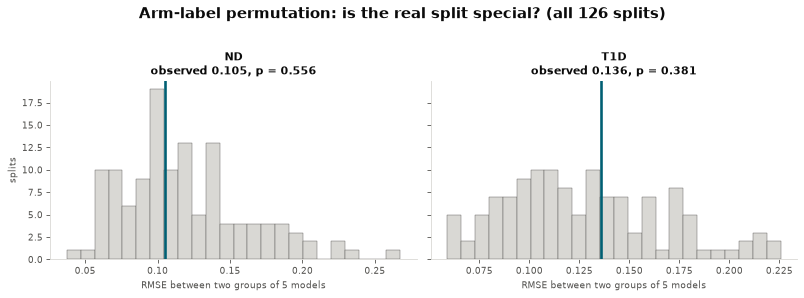

In [26]:
# The arm-label permutation, drawn. The observed split is one bar in its own null distribution.
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(5.4 * len(CONDITIONS), 3.8), sharey=True)
for ax, condition in zip(np.atleast_1d(axes), CONDITIONS):
    mats = ([seed_matrix(flow, GLOBAL_ARM, s, condition) for s in SEEDS]
            + [seed_matrix(flow, COMBINED_ARM, s, condition) for s in SEEDS])
    observed = rmse(np.mean(mats[5:], axis=0), np.mean(mats[:5], axis=0))
    null = []
    for grp in combinations(range(10), 5):
        if 0 not in grp:
            continue
        rest = [i for i in range(10) if i not in grp]
        null.append(rmse(np.mean([mats[i] for i in rest], axis=0),
                         np.mean([mats[i] for i in grp], axis=0)))
    p = float((np.array(null) >= observed).mean())

    ax.hist(null, bins=24, color=figure_style.GRID, edgecolor=figure_style.INK_2, linewidth=0.4)
    ax.axvline(observed, color=ARMS["Local + global"]["color"], lw=2.5)
    ax.set_title(f"{condition}\nobserved {observed:.3f}, p = {p:.3f}",
                 fontsize=11, fontweight=st.general["title_fontweight"])
    ax.set_xlabel("RMSE between two groups of 5 models")
axes[0].set_ylabel("splits") if len(CONDITIONS) > 1 else None
fig.suptitle("Arm-label permutation: is the real split special? (all 126 splits)", y=1.03, **st.title_kw)
fig.tight_layout()
fig.savefig(FIG_DIR / "net_flow_arm_permutation.png", dpi=300, bbox_inches="tight")
plt.show()

## CLS token

Two directions, both read off the same relevance matrix in `get_model_output`:

* `_cls_horizontal` = `I[-1, :-1]` -- how much each **cell contributes to the CLS token**, i.e. to
  the window-level summary the graph-level head would read.
* `_cls_vertical` = `I[:-1, -1]` -- how much the **CLS token contributes to each cell**.

Both are min-max scaled within each window by `scale_cls_by_sample` before aggregation, because the
raw relevances are ~1e-6 and scale with the window's cell count.

`plot_adata_grouped_heatmaps` is the repo's side-by-side heatmap with a shared colour scale, so the
two arms are directly comparable panel to panel.

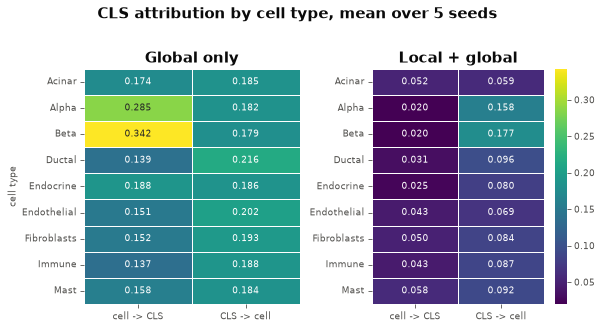

In [27]:
from interscale.evaluation.graph_classification import plot_adata_grouped_heatmaps

# Cross-seed mean per cell type, per arm. Built as a minimal AnnData per arm because
# plot_adata_grouped_heatmaps takes AnnData objects and groups them itself.
cls_mean = cls.groupby(["arm", CELL_TYPE_COL], observed=True)[CLS_SCALED].mean().reset_index()
cls_sd = cls.groupby(["arm", CELL_TYPE_COL], observed=True)[CLS_SCALED].std().reset_index()

adata_dict = {}
for arm in ARMS:
    obs = cls_mean[cls_mean["arm"] == arm].set_index(CELL_TYPE_COL).reindex(CELL_TYPES).reset_index()
    obs[CELL_TYPE_COL] = pd.Categorical(obs[CELL_TYPE_COL], categories=CELL_TYPES, ordered=True)
    # A positional index, NOT the cell type: AnnData keeps the index name, and pandas refuses to
    # group by a label that is both an index level and a column ("is both an index level and a
    # column label, which is ambiguous").
    obs.index = pd.Index([f"{arm}_{i}" for i in range(len(obs))], name=None)
    adata_dict[arm] = ad.AnnData(np.empty((len(obs), 0), dtype=np.float32), obs=obs)


# The heatmap columns come out named `mean__cls_horizontal_scaled`, which is unreadable on an
# axis. Relabelled after the fact because plot_adata_grouped_heatmaps derives those names itself.
CLS_LABELS = {"_cls_horizontal_scaled": "cell -> CLS", "_cls_vertical_scaled": "CLS -> cell"}


def tidy_cls_heatmap(fig, n_panels, suptitle, out_path):
    # fig.axes is [panel_0 ... panel_n-1, colorbar]; only the panels get relabelled. Saved here
    # rather than through the function's own save_path, so the file matches what is displayed.
    for i, ax in enumerate(fig.axes[:n_panels]):
        ax.set_xticklabels([CLS_LABELS[c] for c in CLS_SCALED], rotation=0)
        ax.set_ylabel("cell type" if i == 0 else "")
    fig.suptitle(suptitle, y=1.03, **st.title_kw)
    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")


fig = plot_adata_grouped_heatmaps(
    adata_dict,
    group_by=CELL_TYPE_COL,
    value_cols=CLS_SCALED,
    split_key=None,  # the analysis slide is entirely `test`, so there is nothing to filter
    figsize=(4.0 * len(adata_dict), 4.2),
    cmap=st.continuous_cmap,
    annot=True,
    fmt=".3f",
    agg_func="mean",
)
tidy_cls_heatmap(
    fig,
    len(adata_dict),
    f"CLS attribution by cell type, mean over {len(SEEDS)} seeds",
    FIG_DIR / "cls_by_celltype.png",
)
plt.show()

### Split by condition

The panel above pools ND and T1D. This one does not. The four panels share one colour scale, so a
difference between conditions within an arm and a difference between arms within a condition are
read off the same ramp.

This matters here because the slide is 51,365 ND cells against 100,230 T1D, and the CLS values are
min-max scaled **within each window** -- so a shift in which condition's windows carry the extreme
cells would move the pooled means without either arm changing how it attributes.

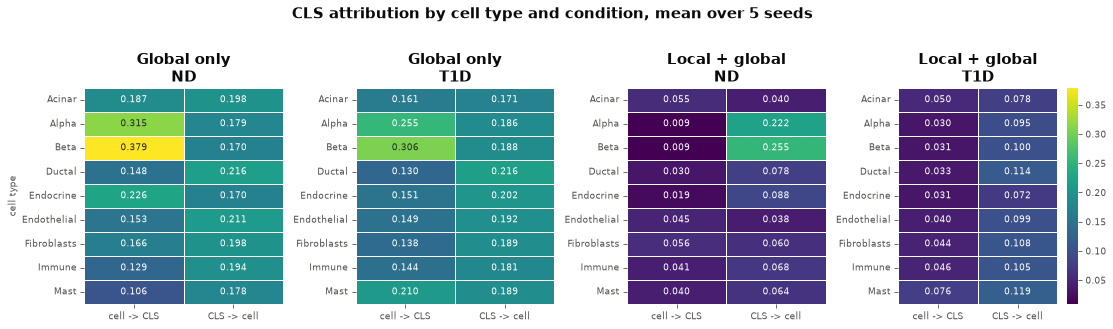

In [28]:
# Per (arm, condition), cross-seed mean per cell type. Dict insertion order is panel order, so the
# two arms sit next to each other within each condition block.
adata_cond = {}
for arm in ARMS:
    for condition in CONDITIONS:
        sub = cls[(cls["arm"] == arm) & (cls[CONDITION_COL] == condition)]
        obs = (
            sub.groupby(CELL_TYPE_COL, observed=True)[CLS_SCALED]
            .mean()
            .reindex(CELL_TYPES)
            .reset_index()
        )
        obs[CELL_TYPE_COL] = pd.Categorical(obs[CELL_TYPE_COL], categories=CELL_TYPES, ordered=True)
        # Positional index: AnnData keeps the index name, and pandas refuses to group by a label
        # that is both an index level and a column.
        obs.index = pd.Index([f"{arm}_{condition}_{i}" for i in range(len(obs))], name=None)
        adata_cond[f"{arm}\n{condition}"] = ad.AnnData(
            np.empty((len(obs), 0), dtype=np.float32), obs=obs
        )

fig = plot_adata_grouped_heatmaps(
    adata_cond,
    group_by=CELL_TYPE_COL,
    value_cols=CLS_SCALED,
    split_key=None,
    figsize=(3.7 * len(adata_cond), 4.2),
    cmap=st.continuous_cmap,
    annot=True,
    fmt=".3f",
    agg_func="mean",
)
tidy_cls_heatmap(
    fig,
    len(adata_cond),
    f"CLS attribution by cell type and condition, mean over {len(SEEDS)} seeds",
    FIG_DIR / "cls_by_celltype_condition.png",
)
plt.show()

In [29]:
# Per condition, with the cross-seed SD, and whether the arm difference clears it.
cls_c_mean = cls.groupby(["arm", CONDITION_COL, CELL_TYPE_COL], observed=True)[CLS_SCALED].mean()
cls_c_sd = cls.groupby(["arm", CONDITION_COL, CELL_TYPE_COL], observed=True)[CLS_SCALED].std()

for col in CLS_SCALED:
    t = pd.DataFrame(
        {
            "global mean": cls_c_mean.xs("Global only")[col],
            "global SD": cls_c_sd.xs("Global only")[col],
            "combined mean": cls_c_mean.xs("Local + global")[col],
            "combined SD": cls_c_sd.xs("Local + global")[col],
        }
    )
    t["difference"] = t["combined mean"] - t["global mean"]
    t["exceeds seed spread"] = t["difference"].abs() > (t["global SD"] + t["combined SD"])
    print(f"===== {col} =====")
    print(t.round(4).to_string())
    print()

===== _cls_horizontal_scaled =====
                            global mean  global SD  combined mean  combined SD  difference  exceeds seed spread
condition cell_type_coarse                                                                                     
ND        Acinar                 0.1870     0.1003         0.0549       0.0734     -0.1321                False
          Alpha                  0.3154     0.2255         0.0093       0.0037     -0.3061                 True
          Beta                   0.3792     0.2423         0.0092       0.0082     -0.3700                 True
          Ductal                 0.1484     0.0958         0.0296       0.0319     -0.1187                False
          Endocrine              0.2256     0.2072         0.0188       0.0190     -0.2068                False
          Endothelial            0.1525     0.0782         0.0455       0.0779     -0.1070                False
          Fibroblasts            0.1663     0.0599         0.0556    

In [30]:
# The same contrast as numbers, with the cross-seed SD beside it. Same rule as for the flows: a
# difference smaller than the seed spread of either arm is not a difference.
tab = (
    cls_mean.melt(id_vars=["arm", CELL_TYPE_COL], var_name="direction", value_name="mean")
    .merge(
        cls_sd.melt(id_vars=["arm", CELL_TYPE_COL], var_name="direction", value_name="sd"),
        on=["arm", CELL_TYPE_COL, "direction"],
    )
    .pivot(index=[CELL_TYPE_COL, "direction"], columns="arm", values=["mean", "sd"])
)
tab[("difference", "")] = tab[("mean", "Local + global")] - tab[("mean", "Global only")]
tab.round(4)

mean                 \
arm                                     Global only Local + global   
cell_type_coarse direction                                           
Acinar           _cls_horizontal_scaled      0.1740         0.0524   
                 _cls_vertical_scaled        0.1846         0.0589   
Alpha            _cls_horizontal_scaled      0.2854         0.0199   
                 _cls_vertical_scaled        0.1824         0.1584   
Beta             _cls_horizontal_scaled      0.3424         0.0200   
                 _cls_vertical_scaled        0.1788         0.1773   
Ductal           _cls_horizontal_scaled      0.1394         0.0313   
                 _cls_vertical_scaled        0.2160         0.0959   
Endocrine        _cls_horizontal_scaled      0.1882         0.0248   
                 _cls_vertical_scaled        0.1861         0.0799   
Endothelial      _cls_horizontal_scaled      0.1506         0.0429   
                 _cls_vertical_scaled        0.2015         0.0687   
Fibroblasts      _cls_horizontal_scaled      0.1519         0.0498   
                 _cls_vertical_scaled        0.1933         0.0843   
Immune           _cls_horizontal_scaled      0.1368         0.0433   
                 _cls_vertical_scaled        0.1876         0.0865   
Mast             _cls_horizontal_scaled      0.1579         0.0580   
                 _cls_vertical_scaled        0.1839         0.0915   

                                                 sd                difference  
arm                                     Global only Local + global             
cell_type_coarse direction                                                     
Acinar           _cls_horizontal_scaled      0.0815         0.0677    -0.1216  
                 _cls_vertical_scaled        0.0778         0.0567    -0.1257  
Alpha            _cls_horizontal_scaled      0.2356         0.0241    -0.2655  
                 _cls_vertical_scaled        0.1269         0.1634    -0.0240  
Beta             _cls_horizontal_scaled      0.2415         0.0247    -0.3224  
                 _cls_vertical_scaled        0.1224         0.1921    -0.0014  
Ductal           _cls_horizontal_scaled      0.0805         0.0255    -0.1081  
                 _cls_vertical_scaled        0.0787         0.0984    -0.1201  
Endocrine        _cls_horizontal_scaled      0.1727         0.0208    -0.1634  
                 _cls_vertical_scaled        0.1088         0.0616    -0.1063  
Endothelial      _cls_horizontal_scaled      0.0673         0.0549    -0.1077  
                 _cls_vertical_scaled        0.0817         0.0713    -0.1328  
Fibroblasts      _cls_horizontal_scaled      0.0586         0.0516    -0.1021  
                 _cls_vertical_scaled        0.0821         0.0810    -0.1090  
Immune           _cls_horizontal_scaled      0.0803         0.0445    -0.0935  
                 _cls_vertical_scaled        0.0856         0.0900    -0.1011  
Mast             _cls_horizontal_scaled      0.1231         0.0638    -0.0999  
                 _cls_vertical_scaled        0.0560         0.0696    -0.0923

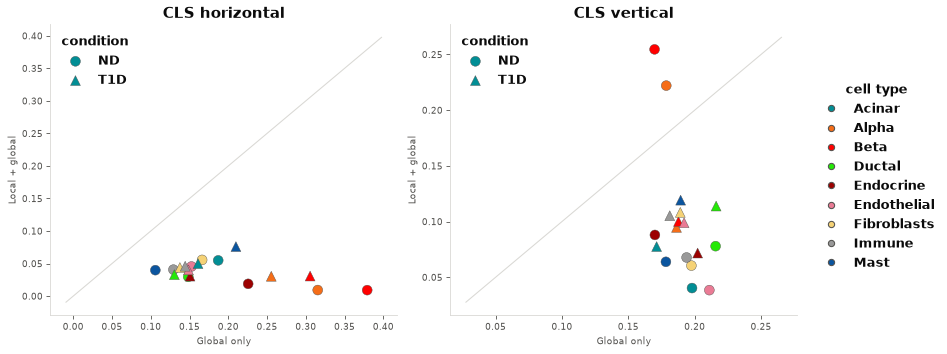

In [31]:
# Per condition, so a difference that is really a difference in ND-vs-T1D composition is visible
# as one. Points are cell types; the diagonal is "the two arms agree".
fig, axes = plt.subplots(1, len(CLS_SCALED), figsize=(5.4 * len(CLS_SCALED), 4.8))
cls_cond = cls.groupby(["arm", CELL_TYPE_COL, CONDITION_COL], observed=True)[CLS_SCALED].mean().reset_index()

for ax, col in zip(np.atleast_1d(axes), CLS_SCALED):
    wide = cls_cond.pivot(index=[CELL_TYPE_COL, CONDITION_COL], columns="arm", values=col).reset_index()
    for condition, marker in zip(CONDITIONS, ["o", "^"]):
        s = wide[wide[CONDITION_COL] == condition]
        ax.scatter(
            s["Global only"],
            s["Local + global"],
            c=[CT_COLORS[t] for t in s[CELL_TYPE_COL]],
            marker=marker,
            s=90,
            edgecolor=figure_style.INK_2,
            linewidth=0.4,
            label=condition,
        )
    lo = min(wide["Global only"].min(), wide["Local + global"].min())
    hi = max(wide["Global only"].max(), wide["Local + global"].max())
    pad = 0.05 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color=figure_style.GRID, lw=1, zorder=0)
    ax.set_xlabel("Global only")
    ax.set_ylabel("Local + global")
    ax.set_title(col.replace("_cls_", "CLS ").replace("_scaled", ""), **st.title_kw)
    ax.legend(title="condition", **st.legend_kw)

handles = [
    plt.Line2D([], [], marker="o", ls="", color=c, label=t, markeredgecolor=figure_style.INK_2)
    for t, c in CT_COLORS.items()
    if t in CELL_TYPES
]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), title="cell type", **st.legend_kw)
fig.tight_layout()
fig.savefig(FIG_DIR / "cls_arm_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

## Reading the result

The three readouts come out differently, and the difference is the finding.

### Reconstruction: the local component helps, reproducibly

`val_concordance_corr` 0.0154 +/- 0.0004 (local + global) against 0.0054 +/- 0.0006 (global only) --
2.9x, with a seed spread far smaller than the gap, for 769,318 parameters against 391,891. Test
concordance orders the same way (0.0157 +/- 0.0005 against 0.0074 +/- 0.0009). `val_r2` is negative
for both arms (~ -0.017): neither beats a per-gene mean predictor in absolute terms, which is this
dataset's known calibration problem and not something the ablation introduces.

### Directed attention: the arms rank interaction partners the same way

On the DIRECTED attention (`compute_net=False`, i.e. attention weight rather than a signed
difference), Kendall's tau between the arms, averaged over senders, is **0.675 (ND)** and **0.492
(T1D)** -- at or above the within-arm seed-to-seed reference of 0.489 and 0.461. Two models that
differ by the entire local component rank each sender's receivers as consistently as two seeds of
one model do.

**No sender falls below its own seed-noise floor** in either condition. Alpha (tau -0.071) and Beta
(-0.357) under T1D look like disagreement until the per-sender control is read: those two senders
have within-arm mean tau of 0.043 and 0.007, with 5th percentiles of -0.432 and -0.504. They are
unstable in *both* arms, not reshuffled by the ablation. Reading their low cross-arm tau as a
disease-relevant ablation effect would be the single easiest mistake to make in this analysis.

So: removing the local component does not detectably change which partners the attention
emphasises.

### Net flow: not resolved at five seeds

The net flow is the *antisymmetric residual* of that same attention -- `agg.T - agg` -- and it
removes exactly the shared structure the tau above is measuring. What is left does not reproduce.

| statistic (upper triangle, 36 pairs) | ND | T1D |
| --- | --- | --- |
| RMSE between arm mean matrices | 0.105 | 0.136 |
| **arm-label permutation, p (exact, 126 splits)** | **0.556** | **0.381** |
| median RMSE between two seeds, global only | 0.263 | 0.348 |
| median RMSE between two seeds, local + global | 0.277 | 0.208 |
| Pearson / Spearman between arm means | +0.213 / +0.087 | -0.405 / -0.272 |
| same, within arm (seed pairs) | -0.010 / -0.039 | -0.035 / -0.051 |
| split-half reliability of one arm's mean | 0.028 | 0.041 |
| cell-type relabelling null, p | 0.047 | 0.830 |

The decisive line is the permutation test. Pooling the ten models of a condition and splitting them
into two groups of five in all 126 distinct ways, the true architecture split is entirely typical of
the null (p = 0.556, 0.381). The between-arm RMSE is no larger than the RMSE between two
independently seeded runs of one arm.

The split-half reliability explains why nothing else in that table can be interpreted: a per-arm
mean net-flow matrix is not estimable from five seeds (0.028, 0.041). A correlation is bounded by
the geometric mean of the reliabilities of the two quantities entering it, so the +0.213 and -0.405
between-arm correlations are correlations between two unmeasurable quantities and are evidence for
nothing in either direction. Consistently, none of the twelve largest sender-receiver differences
exceeds the summed cross-seed SD of the two arms.

**Do not read the ND-versus-T1D contrast as a condition effect.** The seed spread is itself larger
in T1D (within-arm median 0.348 against 0.263 for the global-only arm), so relative to its own noise
floor T1D shows slightly *less* arm divergence than ND, not more. The same applies to the
least-divergent-pair panel: 0.133 (ND) and 0.202 (T1D) are minima over 25 pairings, selected for
smallness, and both sit below the within-arm scale.

### CLS: a large and systematic shift

Every one of the nine cell types moves the same way in the cell -> CLS direction: the combined model
puts 3-7x LESS window-min-max-scaled relevance on cells than the global-only model. Since the
scaling is per window, a lower mean means a more skewed distribution -- the combined model
**concentrates** the window summary on a few cells where the global-only model spreads it. Under ND
this is resolved for Alpha (-0.306) and Beta (-0.370), whose differences exceed the summed seed
spread of both arms; under T1D the same types move the same way with roughly doubled variance, and
only Ductal, Endothelial and Fibroblasts clear it.

The CLS -> cell direction is why the condition split was worth drawing. Pooled, Alpha and Beta look
unchanged (-0.024, -0.001). Split, they are two opposing effects cancelling: under **ND** both rise
under the combined model (Alpha +0.044, Beta +0.085) while the other seven types fall, six clearing
the seed spread; under **T1D** all nine fall and none clears it. Read the per-condition panel, not
the pooled one, for this direction.

The ranking change is worth noticing but not claiming. Global-only ranks the endocrine cells highest
on cell -> CLS (Beta 0.379, Alpha 0.315 under ND, against ~0.10-0.23 for everything else); the
combined model ranks them lowest. Its SDs are the size of the spread between its own cell types, so
the inversion is suggestive rather than established.

### What this supports

The local component measurably improves reconstruction and systematically changes the CLS
attribution. It does **not** detectably change which interaction partners the attention emphasises
(tau at or above the within-arm reference), and the net flow is not resolved at five seeds
(permutation p = 0.556 / 0.381).

Two candidates for the net-flow instability, both open. The **per-window max-abs normalisation**
inside `compute_hierarchical_net_flow` divides each window by its own largest absolute entry before
windows are averaged, so a window with no structure is amplified to the scale of one that has some;
with 215 windows of very uneven size that alone can dominate. And the antisymmetric residual may
simply carry no stable signal at this scale -- which the directed-attention tau makes plausible,
since the shared structure it removes is the part that does reproduce.

Undertraining is **not** among the candidates: the same ablation on legnini23 with models trained to
a median of 227-293 epochs, at the best reconstruction scores obtained on that dataset
(concordance 0.1996 +/- 0.0026), shows the same net-flow instability. See
`notebooks/legnini_23/5_component_ablation_legnini_gene.ipynb`.